# Q1D | Step by Step

A scratch notebook for building intuition, one idea at a time. Nothing here is the submission.

Each step: run the cells, look at the output, then answer the questions at the bottom **in your own words**. Move on only when the answers feel obvious.

# Step 1 | One Feature, One Line

**Goal:** see what a linear regression actually does, and what RMSE means, on the simplest possible case: one feature (Healthy life expectancy) predicting Life Ladder.

## Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

from Q1.consts import TRAIN_PATH

train_df = pd.read_csv(TRAIN_PATH)

FEATURE = "Healthy life expectancy at birth"
TARGET = "Life Ladder"

# keep only the rows where both columns have a value
df = train_df[[FEATURE, TARGET]].dropna()

x = df[[FEATURE]]   # double brackets: sklearn wants a table of features, even if there is only one
y = df[TARGET]

print(f"Rows used: {len(df):,} of {len(train_df):,}")
df.head()

Rows used: 1,522 of 1,559


,Healthy life expectancy at birth,Life Ladder
0,64.22,4.930
1,67.48,5.367
2,72.60,7.375
3,60.64,4.613
4,65.80,6.180


## Fit the line

A linear regression finds the one straight line `Life Ladder = a + b × life expectancy` that misses the points by the least, overall.
- `a` (intercept): the predicted Life Ladder when life expectancy is 0. It only anchors the line.
- `b` (slope): how much the predicted Life Ladder goes up for each extra year of life expectancy.

In [2]:
model = LinearRegression()
model.fit(x, y)

a = model.intercept_
b = model.coef_[0]

print(f"Life Ladder = {a:.3f} + {b:.4f} × life expectancy")
print(f"Each extra year of life expectancy adds {b:.4f} to the predicted Life Ladder")

Life Ladder = -1.665 + 0.1126 × life expectancy
Each extra year of life expectancy adds 0.1126 to the predicted Life Ladder


## See the line

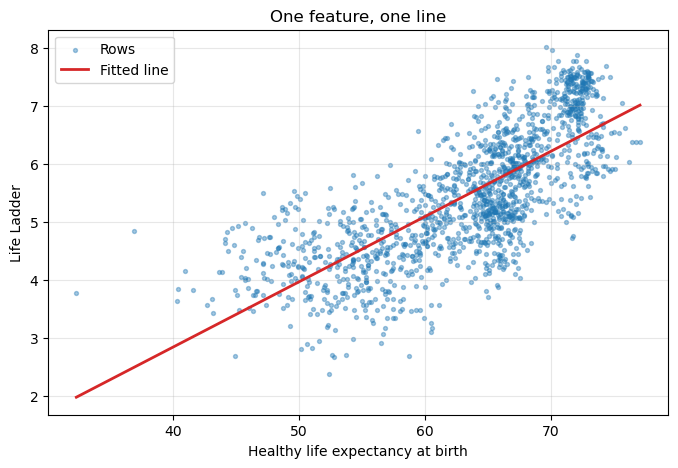

In [3]:
grid = pd.DataFrame({FEATURE: np.linspace(x[FEATURE].min(), x[FEATURE].max(), 100)})

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x[FEATURE], y, s=8, alpha=0.4, label="Rows")
ax.plot(grid[FEATURE], model.predict(grid), color="C3", linewidth=2, label="Fitted line")
ax.set_xlabel(FEATURE)
ax.set_ylabel(TARGET)
ax.set_title("One feature, one line")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## How far off is it? (RMSE, by hand)

For every row: **miss = actual Life Ladder - predicted Life Ladder**.

RMSE squares every miss (so misses above and below the line both count, and big misses count extra), averages them, then takes the square root to get back to Life Ladder units. So RMSE reads as **"the model typically misses by about this many Life Ladder points."**

In [4]:
pred = model.predict(x)
miss = y - pred

examples = pd.DataFrame({
	"life expectancy": x[FEATURE],
	"actual": y,
	"predicted": pred.round(3),
	"miss": miss.round(3),
}).head(8)
display(examples)

rmse = np.sqrt(np.mean(miss ** 2))
print(f"RMSE: {rmse:.3f} Life Ladder points")

,life expectancy,actual,predicted,miss
0,64.22,4.930,5.568,-0.638
1,67.48,5.367,5.935,-0.568
2,72.60,7.375,6.512,0.863
3,60.64,4.613,5.165,-0.552
4,65.80,6.180,5.746,0.434
5,51.58,5.013,4.144,0.869
6,62.08,6.696,5.327,1.369
7,66.66,5.767,5.843,-0.076


RMSE: 0.741 Life Ladder points


## Compared to what?

An RMSE number means nothing on its own. The simplest possible "model" ignores life expectancy and always predicts the average Life Ladder. Its RMSE is the bar the line has to beat.

In [5]:
average_guess = y.mean()
rmse_average = np.sqrt(np.mean((y - average_guess) ** 2))

print(f"Always guess the average ({average_guess:.3f}): RMSE {rmse_average:.3f}")
print(f"Fitted line:                       RMSE {rmse:.3f}")
print(f"The line cuts the typical miss by {1 - rmse / rmse_average:.0%}")

Always guess the average (5.468): RMSE 1.122
Fitted line:                       RMSE 0.741
The line cuts the typical miss by 34%


## One honest caveat

The RMSE above was measured on **the same rows the line was fit on**. That is like grading a student on the exact questions they studied. Step 2 fixes this with cross-validation.

## Your Turn

Answer each in one or two sentences, in your own words, right here:

1. Looking at the plot, where does the straight line fit the points well, and where does it miss badly?
2. What does the RMSE number mean, in plain English?
3. Why is "always guess the average" a useful thing to compare against?

_Your answers:_

1. Most of the data seems to be grouped in the 60 plus healthy life expectancy at birth, so the line misses more egregiously. At lower healthy life expectancy at birth values
2. The RSME looks at the overall error that the line or the model predicts across all the available points
3. It is a common baseline that can be achieved very easily and simply without any of the complexity of building any kind of linear model at all. So it is the baseline that any model must beat

---

# Step 2 | Why Cross-Validation

**Goal:** see why a model has to be graded on rows it never saw, why one grade is not enough, and how to tell a real improvement from luck.

## 2a. Grade on rows the model never saw

Split the rows once: the line learns from 75% (**train**) and is graded on the other 25% (**validation**), which it never saw while learning.

In [6]:
from sklearn.model_selection import KFold, train_test_split


def rmse_of(actual, predicted):
	return np.sqrt(np.mean((actual - predicted) ** 2))


x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=0.25, random_state=42)

split_model = LinearRegression().fit(x_train, y_train)

print(f"Train rows: {len(x_train):,} | Validation rows: {len(x_val):,}")
print(f"Train RMSE (rows it learned from): {rmse_of(y_train, split_model.predict(x_train)):.3f}")
print(f"Validation RMSE (rows it never saw): {rmse_of(y_val, split_model.predict(x_val)):.3f}")

Train rows: 1,141 | Validation rows: 381
Train RMSE (rows it learned from): 0.747
Validation RMSE (rows it never saw): 0.723


## 2b. One split is luck of the draw

Which rows land in validation is random. A different split gives a different grade, for the **exact same model**.

4-fold cross-validation splits the rows into 4 parts and takes turns: each part is the validation set once, while the line learns from the other 3. That gives 4 grades. Repeating it with 5 different shuffles gives 20 grades.

In [7]:
SEEDS = [42, 0, 1, 2, 3]


def cv_scores(data, columns):
	"""Validation RMSE of a line fit on `columns`, for each of the 20 folds (4 folds x 5 shuffles)."""
	scores = []
	for seed in SEEDS:
		for train_rows, val_rows in KFold(n_splits=4, shuffle=True, random_state=seed).split(data):
			train, val = data.iloc[train_rows], data.iloc[val_rows]
			fold_model = LinearRegression().fit(train[columns], train[TARGET])
			scores.append(rmse_of(val[TARGET], fold_model.predict(val[columns])))
	return np.array(scores)


life_scores = cv_scores(df, [FEATURE])

print("The first 4 folds (one shuffle):", life_scores[:4].round(3))
print(f"All 20 folds: lowest {life_scores.min():.3f}, highest {life_scores.max():.3f}")
print(f"Mean {life_scores.mean():.3f}, sd {life_scores.std(ddof=1):.3f}")

The first 4 folds (one shuffle): [0.723 0.762 0.766 0.714]
All 20 folds: lowest 0.698, highest 0.795
Mean 0.741, sd 0.026


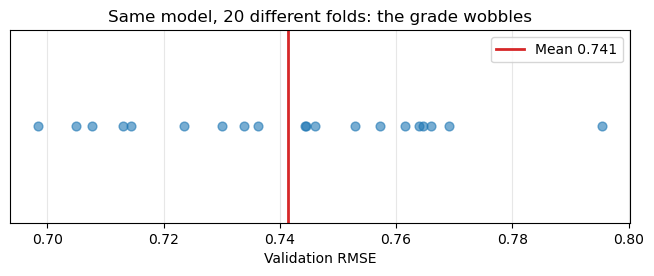

In [8]:
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.scatter(life_scores, np.zeros_like(life_scores), s=40, alpha=0.6)
ax.axvline(life_scores.mean(), color="C3", linewidth=2, label=f"Mean {life_scores.mean():.3f}")
ax.set_yticks([])
ax.set_xlabel("Validation RMSE")
ax.set_title("Same model, 20 different folds: the grade wobbles")
ax.grid(alpha=0.3, axis="x")
ax.legend()
plt.show()

## 2c. Real improvement or luck?

Three models, all graded on **the same 20 folds** (same rows in every fold), so the only thing that differs is the model:

- **A:** life expectancy only (the line from Step 1)
- **B:** A + a column of **pure random noise**. It carries no information, so it cannot truly help.
- **C:** A + Log GDP per capita, a column that does carry information.

All three use only rows that have life expectancy and GDP, so they are graded on identical rows.

In [9]:
rng = np.random.default_rng(0)

df_two = train_df[[FEATURE, "Log GDP per capita", TARGET]].dropna().copy()
df_two["random noise"] = rng.normal(size=len(df_two))

scores_a = cv_scores(df_two, [FEATURE])
scores_b = cv_scores(df_two, [FEATURE, "random noise"])
scores_c = cv_scores(df_two, [FEATURE, "Log GDP per capita"])

summary = pd.DataFrame({
	"mean RMSE": [scores_a.mean(), scores_b.mean(), scores_c.mean()],
	"change vs A": [0.0, scores_b.mean() - scores_a.mean(), scores_c.mean() - scores_a.mean()],
	"folds where it beats A": pd.array([None, (scores_b < scores_a).sum(), (scores_c < scores_a).sum()], dtype="Int64"),
}, index=["A: life expectancy", "B: A + random noise", "C: A + GDP"])

summary.round(4)

,mean RMSE,change vs A,folds where it beats A
A: life expectancy,0.7385,0.0000,<NA>
B: A + random noise,0.7392,0.0007,8
C: A + GDP,0.6664,-0.0720,20


The table only shows averages. The plot below shows each fold: how much B and C changed the RMSE **on that fold**, compared with A. Below 0 means better than A. Both panels use the same scale, so the bar sizes are directly comparable.

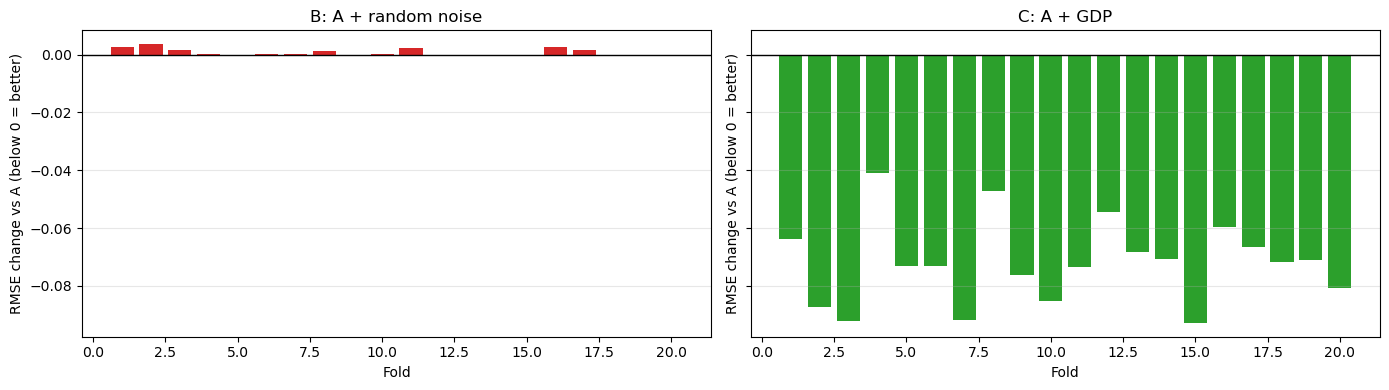

In [10]:
fold = np.arange(1, len(scores_a) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, scores, title in [(axes[0], scores_b, "B: A + random noise"), (axes[1], scores_c, "C: A + GDP")]:
	diff = scores - scores_a
	ax.bar(fold, diff, color=np.where(diff < 0, "C2", "C3"))
	ax.axhline(0, color="black", linewidth=1)
	ax.set_xlabel("Fold")
	ax.set_ylabel("RMSE change vs A (below 0 = better)")
	ax.set_title(title)
	ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

## The idea to keep

A model is only really better if it wins **consistently across the folds**, by more than the normal fold-to-fold wobble. A tiny average win that flips between folds is luck.

The big notebook's `Δ / SE` and verdict columns were this exact check, done with a formula instead of by eye.

## Your Turn

1. Why is the validation RMSE a more honest number than the training RMSE?
2. The same model got 20 different grades. What does that mean for comparing two models using a single split?
3. Looking at the per-fold plot, how can you tell the random noise column is useless and GDP is not?
4. In 2a, look at which RMSE came out lower, train or validation. Using what 2b shows, how could that happen?

_Your answers:_

1. Because it's a number based on the result of the model predicting from values it was not trained on. It is a true test of the actual quality of the model against data it has not seen.
2. Taking the average or the median of multiple experiments or grades gives you a better understanding of how the system is working overall. In particular, using the cross-fold method. Each one of these grades is a different grouping of training versus validation data, where validation data's importance has been explained in number one. So the mean over these different folds and these different grades gives you a true understanding of what the model is doing under varying circumstances.
3. You can see the random noise is not consistently beating. The baseline.
4. 2A shows that the root mean squared error was best for validation and using what 2B shows that can happen because of that particular individual split of training versus validation data

---

# Step 3 | The Hinge

**Goal:** see why the straight line is the wrong shape, how a hinge lets the line bend, and check with Step 2's tools whether the improvement is real.

## 3a. The pattern in the misses

Step 1's miss table hinted at a pattern: too low at both ends, too high in the middle. Here are **all** the misses at once. Each dot is a row's miss; the red line is the average miss within each 2-year band of life expectancy.

If the straight line were the right shape, the red line would wobble around 0 with no pattern.

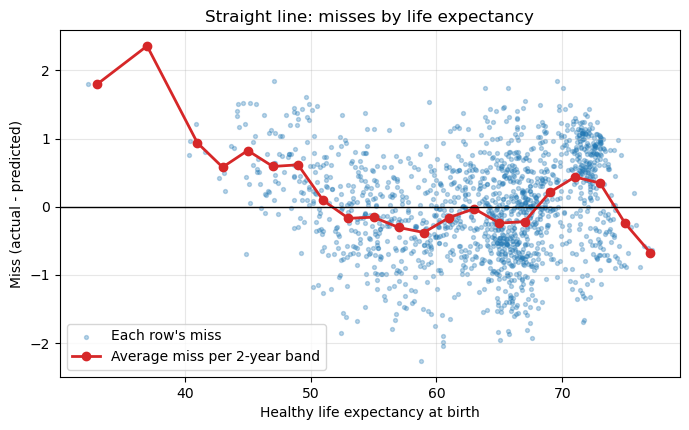

In [11]:
def binned_miss(values, misses, width=2):
	"""Average miss within each `width`-year band, so the pattern is easy to see."""
	bands = (values // width) * width + width / 2
	return misses.groupby(bands).mean()


straight_miss = y - model.predict(x)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x[FEATURE], straight_miss, s=8, alpha=0.3, label="Each row's miss")
avg = binned_miss(x[FEATURE], straight_miss)
ax.plot(avg.index, avg.values, color="C3", linewidth=2, marker="o", label="Average miss per 2-year band")
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel(FEATURE)
ax.set_ylabel("Miss (actual - predicted)")
ax.set_title("Straight line: misses by life expectancy")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 3b. What a hinge is

A hinge is one extra column built from life expectancy:

`hinge = max(0, life expectancy - 57.5)`

It is 0 for every row at or below 57.5, and counts the years above 57.5 for every row above it.

In [12]:
T = 57.5

examples = pd.DataFrame({"life expectancy": [45.0, 52.0, 57.5, 60.0, 65.0, 72.0]})
examples["hinge"] = np.maximum(0, examples["life expectancy"] - T)
examples

,life expectancy,hinge
0,45.0,0.0
1,52.0,0.0
2,57.5,0.0
3,60.0,2.5
4,65.0,7.5
5,72.0,14.5


With both columns, the line becomes `Life Ladder = a + b × life expectancy + c × hinge`:

- **Below 57.5** the hinge is 0, so only `b` matters: the slope is `b`.
- **Above 57.5** every extra year raises both columns by 1: the slope is `b + c`.

So it is still a linear regression, but the line is allowed **one bend, at 57.5**.

In [13]:
df_h = df.copy()
df_h["hinge"] = np.maximum(0, df_h[FEATURE] - T)

bent = LinearRegression().fit(df_h[[FEATURE, "hinge"]], df_h[TARGET])
b, c = bent.coef_

print(f"Slope below {T}: {b:.4f} per year")
print(f"Slope above {T}: {b + c:.4f} per year")
print(f"(The straight line used one slope everywhere: {model.coef_[0]:.4f} per year)")

Slope below 57.5: 0.0144 per year
Slope above 57.5: 0.1585 per year
(The straight line used one slope everywhere: 0.1126 per year)


## 3c. See both lines

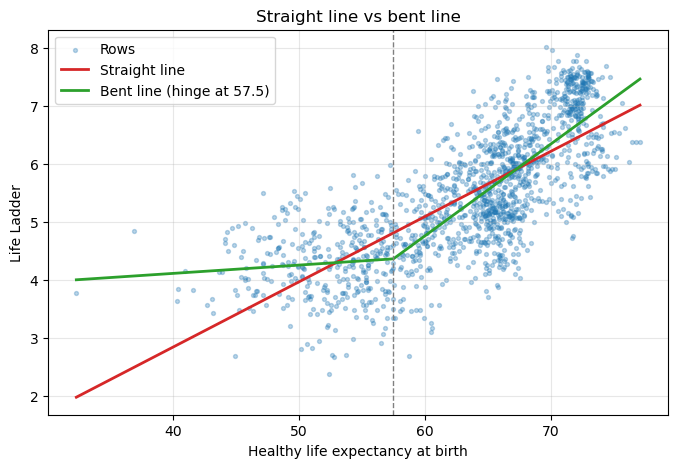

In [14]:
grid_h = pd.DataFrame({FEATURE: np.linspace(df_h[FEATURE].min(), df_h[FEATURE].max(), 200)})
grid_h["hinge"] = np.maximum(0, grid_h[FEATURE] - T)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df_h[FEATURE], df_h[TARGET], s=8, alpha=0.3, label="Rows")
ax.plot(grid_h[FEATURE], model.predict(grid_h[[FEATURE]]), color="C3", linewidth=2, label="Straight line")
ax.plot(grid_h[FEATURE], bent.predict(grid_h[[FEATURE, "hinge"]]), color="C2", linewidth=2, label=f"Bent line (hinge at {T})")
ax.axvline(T, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel(FEATURE)
ax.set_ylabel(TARGET)
ax.set_title("Straight line vs bent line")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 3d. Real improvement or luck?

Step 2's test: the same 20 folds, every model graded on identical rows.

- **A:** life expectancy only (straight line)
- **B:** life expectancy + hinge (bent line)
- **C:** hinge alone (flat below 57.5, rising above)

In [15]:
scores_straight = cv_scores(df_h, [FEATURE])
scores_bent = cv_scores(df_h, [FEATURE, "hinge"])
scores_hinge_only = cv_scores(df_h, ["hinge"])

pd.DataFrame({
	"mean RMSE": [scores_straight.mean(), scores_bent.mean(), scores_hinge_only.mean()],
	"change vs A": [0.0, scores_bent.mean() - scores_straight.mean(), scores_hinge_only.mean() - scores_straight.mean()],
	"folds where it beats A": pd.array([None, (scores_bent < scores_straight).sum(), (scores_hinge_only < scores_straight).sum()], dtype="Int64"),
}, index=["A: straight line", "B: straight + hinge", "C: hinge alone"]).round(4)

,mean RMSE,change vs A,folds where it beats A
A: straight line,0.7414,0.0000,<NA>
B: straight + hinge,0.6946,-0.0468,20
C: hinge alone,0.6949,-0.0464,20


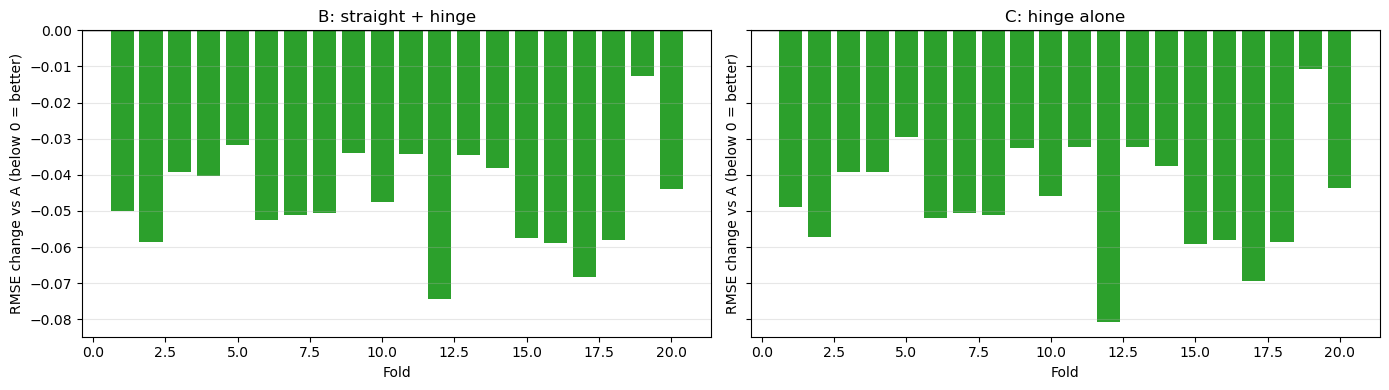

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, scores, title in [(axes[0], scores_bent, "B: straight + hinge"), (axes[1], scores_hinge_only, "C: hinge alone")]:
	diff = scores - scores_straight
	ax.bar(fold, diff, color=np.where(diff < 0, "C2", "C3"))
	ax.axhline(0, color="black", linewidth=1)
	ax.set_xlabel("Fold")
	ax.set_ylabel("RMSE change vs A (below 0 = better)")
	ax.set_title(title)
	ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

## 3e. Did the pattern in the misses go away?

The same miss plot as 3a, now for the bent line.

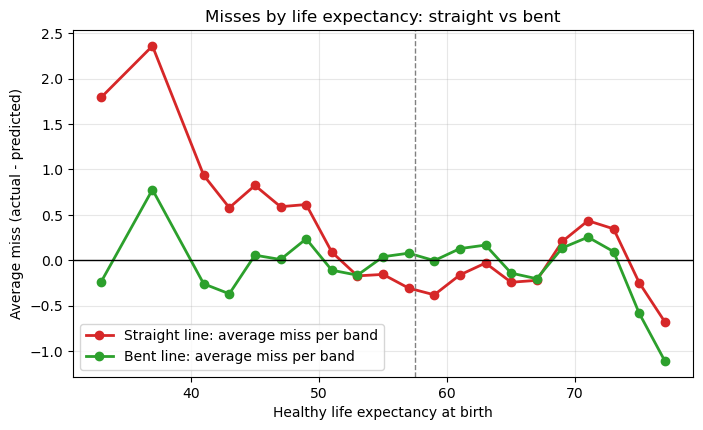

In [17]:
bent_miss = df_h[TARGET] - bent.predict(df_h[[FEATURE, "hinge"]])

fig, ax = plt.subplots(figsize=(8, 4.5))
for misses, label, color in [(straight_miss, "Straight line", "C3"), (bent_miss, "Bent line", "C2")]:
	avg = binned_miss(df_h[FEATURE], misses)
	ax.plot(avg.index, avg.values, color=color, linewidth=2, marker="o", label=f"{label}: average miss per band")
ax.axhline(0, color="black", linewidth=1)
ax.axvline(T, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel(FEATURE)
ax.set_ylabel("Average miss (actual - predicted)")
ax.set_title("Misses by life expectancy: straight vs bent")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 3f. Where does 57.5 come from?

Not from intuition. Try every threshold from 45 to 70 and grade each one with the same 20 folds. The best threshold is where the curve bottoms out.

One caveat: picking the threshold with the same folds that grade it flatters the winner a little, for the same reason a single lucky split can (Step 2). The big notebook's "nested" searches avoided that by picking the threshold inside each fold.

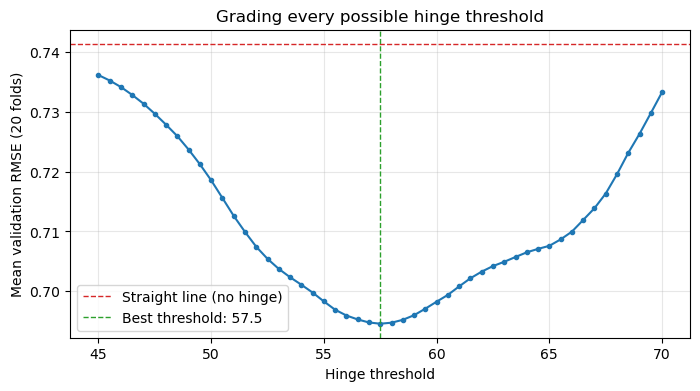

In [18]:
thresholds = np.arange(45, 70.5, 0.5)
threshold_rmse = []
for t in thresholds:
	trial = df.copy()
	trial["hinge"] = np.maximum(0, trial[FEATURE] - t)
	threshold_rmse.append(cv_scores(trial, [FEATURE, "hinge"]).mean())
threshold_rmse = np.array(threshold_rmse)

best_t = thresholds[threshold_rmse.argmin()]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, threshold_rmse, marker="o", markersize=3)
ax.axhline(scores_straight.mean(), color="C3", linestyle="--", linewidth=1, label="Straight line (no hinge)")
ax.axvline(best_t, color="C2", linestyle="--", linewidth=1, label=f"Best threshold: {best_t}")
ax.set_xlabel("Hinge threshold")
ax.set_ylabel("Mean validation RMSE (20 folds)")
ax.set_title("Grading every possible hinge threshold")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## The idea to keep

The process was not a guess:

1. **Look** at the misses: they had a pattern (3a), so the straight line was the wrong shape.
2. **Propose** a shape that matches the pattern: a bend (3b, 3c).
3. **Test** it on the same folds: does it win consistently? (3d)
4. **Check** that the pattern in the misses went away (3e).

Every shape in the big notebook came from this same loop.

## Your Turn

1. In 3a, what pattern in the misses showed that a straight line was the wrong shape?
2. In plain words, what does adding the hinge column let the line do?
3. Is the hinge's improvement real or luck? Name the evidence from 3d.
4. Look at the slope below 57.5 in 3b. What does it say about life expectancy below 57.5, and why does C (hinge alone) score about the same as B?
5. In 3f, what happens to the RMSE if the threshold is badly chosen (ex 45 or 70)? Why?

_Your answers:_

1. The pattern in the misses was not consistent with the straight line, with some areas towards the ends being much bigger than some areas in the middle.
2. The hinge column lets the straight line relationship be split into different groups that better represent those subsets of data points. Well this does not represent a full curve, it takes the linear relationship we are trying to make and puts it to different buckets of data
3. The hinge improvement is real and it is because across all the folds it shows consistent improvement
4. The slope below 57.5 is relatively flat. That means that life expectancy below 57.5 does not carry much signal in terms of the target. I don't know why Hinge alone scored the same as B.
5. If the hinge is badly chosen, then the linear segments on either side of the hinge are worse in the direction of having no hinge at all because the hinge is not reflecitng the best subsection of data.

---

# Step 4 | All Features Together

**Goal:** move from one feature to all eight, add Q1C's shapes, and see which shapes still help once every other feature is in the model.

Every model in this step uses the same rows (the 1,374 rows with no missing values) and the same 20 folds, so they are all directly comparable.

## 4a. From one feature to eight

In [19]:
complete = train_df.dropna().copy()

GDP = "Log GDP per capita"
LIFE = "Healthy life expectancy at birth"
SOCIAL = "Social support"
FREEDOM = "Freedom to make life choices"
GENEROSITY = "Generosity"
CORRUPTION = "Perceptions of corruption"
POS = "Positive affect"
NEG = "Negative affect"
ALL_RAW = [GDP, LIFE, SOCIAL, FREEDOM, GENEROSITY, CORRUPTION, POS, NEG]

complete["Life exp hinge 57.5"] = np.maximum(0, complete[LIFE] - 57.5)

scores_life = cv_scores(complete, [LIFE])
scores_life_hinge = cv_scores(complete, ["Life exp hinge 57.5"])
scores_raw8 = cv_scores(complete, ALL_RAW)

print(f"Rows: {len(complete):,}")
pd.DataFrame({
	"mean RMSE": [scores_life.mean(), scores_life_hinge.mean(), scores_raw8.mean()],
}, index=["Life expectancy only (straight)", "Life expectancy hinge only (Step 3)", "All 8 features, raw"]).round(4)

Rows: 1,374


,mean RMSE
Life expectancy only (straight),0.7349
Life expectancy hinge only (Step 3),0.6829
"All 8 features, raw",0.5458


## 4b. Add Q1C's shapes

Each attribute gets the shape Q1C found for it, built as plain columns with the fixed thresholds:

| Attribute | Shape | Columns |
|---|---|---|
| Log GDP | raw + two bends | raw, hinge at 10.3, hinge at 10.9 |
| Healthy life expectancy | hinge alone | hinge at 57.5 |
| Social support | raw + bend | raw, hinge at 0.84 |
| Freedom | raw + bend | raw, hinge at 0.80 |
| Positive affect | raw + jump | raw, 1 if below 0.749 |
| Corruption | raw + jump | raw, 1 if below 0.58 |
| Negative affect | hinge alone | hinge at 0.20 |
| Generosity | jump alone | 1 if below 0.087 |

A **jump** (indicator) is a column that is 1 below the threshold and 0 above it, so the line steps up or down there. A **bend** (hinge) is the Step 3 corner.

In [20]:
complete["GDP hinge 10.3"] = np.maximum(0, complete[GDP] - 10.3)
complete["GDP hinge 10.9"] = np.maximum(0, complete[GDP] - 10.9)
complete["Social hinge 0.84"] = np.maximum(0, complete[SOCIAL] - 0.84)
complete["Freedom hinge 0.80"] = np.maximum(0, complete[FREEDOM] - 0.80)
complete["Pos affect below 0.749"] = (complete[POS] < 0.749).astype(float)
complete["Corruption below 0.58"] = (complete[CORRUPTION] < 0.58).astype(float)
complete["Neg affect hinge 0.20"] = np.maximum(0, complete[NEG] - 0.20)
complete["Generosity below 0.087"] = (complete[GENEROSITY] < 0.087).astype(float)

# each attribute as raw columns vs shaped columns
RAW = {
	"Log GDP": [GDP], "Life exp": [LIFE], "Social": [SOCIAL], "Freedom": [FREEDOM],
	"Pos affect": [POS], "Corruption": [CORRUPTION], "Neg affect": [NEG], "Generosity": [GENEROSITY],
}
SHAPE = {
	"Log GDP": [GDP, "GDP hinge 10.3", "GDP hinge 10.9"],
	"Life exp": ["Life exp hinge 57.5"],
	"Social": [SOCIAL, "Social hinge 0.84"],
	"Freedom": [FREEDOM, "Freedom hinge 0.80"],
	"Pos affect": [POS, "Pos affect below 0.749"],
	"Corruption": [CORRUPTION, "Corruption below 0.58"],
	"Neg affect": ["Neg affect hinge 0.20"],
	"Generosity": ["Generosity below 0.087"],
}


def columns_for(choice):
	"""Column list for a feature set. `choice` maps each attribute to "shape", "raw" or "drop"."""
	columns = []
	for attribute, pick in choice.items():
		if pick == "shape":
			columns += SHAPE[attribute]
		elif pick == "raw":
			columns += RAW[attribute]
	return columns


ALL_SHAPES = {attribute: "shape" for attribute in SHAPE}
scores_shapes8 = cv_scores(complete, columns_for(ALL_SHAPES))

pd.DataFrame({
	"mean RMSE": [scores_raw8.mean(), scores_shapes8.mean()],
	"change vs raw": [0.0, scores_shapes8.mean() - scores_raw8.mean()],
	"folds where it beats raw": pd.array([None, (scores_shapes8 < scores_raw8).sum()], dtype="Int64"),
}, index=["All 8 raw", "All 8 shapes"]).round(4)

,mean RMSE,change vs raw,folds where it beats raw
All 8 raw,0.5458,0.0000,<NA>
All 8 shapes,0.5166,-0.0292,20


## 4c. Which shapes still help with everything else in the model?

For each attribute, two questions:

- **Alone:** with only that attribute in the model, how much does its shape beat its raw column? (What Q1C measured.)
- **In the full model:** starting from all 8 shapes, how much worse does it get when only this attribute goes back to raw?

Positive numbers mean the shape helps (lower RMSE).

In [21]:
rows = {}
for attribute in SHAPE:
	alone_raw = cv_scores(complete, RAW[attribute]).mean()
	alone_shape = cv_scores(complete, SHAPE[attribute]).mean()

	back_to_raw = cv_scores(complete, columns_for({**ALL_SHAPES, attribute: "raw"}))

	rows[attribute] = {
		"shape gain alone": alone_raw - alone_shape,
		"shape gain in full model": back_to_raw.mean() - scores_shapes8.mean(),
		"folds where shape wins in full model": (scores_shapes8 < back_to_raw).sum(),
	}

ablation = pd.DataFrame(rows).T
ablation["folds where shape wins in full model"] = ablation["folds where shape wins in full model"].astype(int)
ablation.round(4)

,shape gain alone,shape gain in full model,folds where shape wins in full model
Log GDP,0.0479,0.0055,20
Life exp,0.0519,0.0102,20
Social,0.0638,0.0042,18
Freedom,0.0309,-0.0001,7
Pos affect,0.0131,0.0005,14
Corruption,0.0150,-0.0004,13
Neg affect,0.0064,-0.0001,5
Generosity,0.0199,-0.0004,8


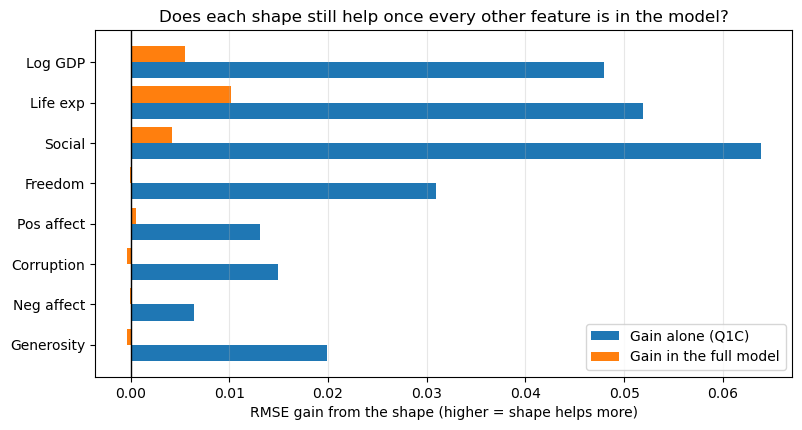

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(ablation))
ax.barh(positions + 0.2, ablation["shape gain alone"], height=0.4, label="Gain alone (Q1C)")
ax.barh(positions - 0.2, ablation["shape gain in full model"], height=0.4, label="Gain in the full model")
ax.set_yticks(positions)
ax.set_yticklabels(ablation.index)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("RMSE gain from the shape (higher = shape helps more)")
ax.set_title("Does each shape still help once every other feature is in the model?")
ax.grid(alpha=0.3, axis="x")
ax.legend()
plt.show()

## 4d. Can two attributes be dropped entirely?

Q1C flagged Negative affect and Generosity as weak. Starting from all 8 shapes, drop each one completely.

In [23]:
drops = {}
for attribute in ["Neg affect", "Generosity"]:
	dropped = cv_scores(complete, columns_for({**ALL_SHAPES, attribute: "drop"}))
	drops[f"drop {attribute}"] = {
		"change vs all 8 shapes": dropped.mean() - scores_shapes8.mean(),
		"folds where dropping is worse": int((dropped > scores_shapes8).sum()),
	}

drop_table = pd.DataFrame(drops).T
drop_table["folds where dropping is worse"] = drop_table["folds where dropping is worse"].astype(int)
drop_table.round(4)

,change vs all 8 shapes,folds where dropping is worse
drop Neg affect,-0.0002,10
drop Generosity,-0.0004,10


## 4e. The selected feature set

Keep a shape only where it still helps in the full model; otherwise use the simpler option (raw, or drop).

In [24]:
SELECTED = {
	"Log GDP": "shape", "Life exp": "shape", "Social": "shape",
	"Freedom": "raw", "Pos affect": "raw", "Corruption": "raw",
	"Neg affect": "drop", "Generosity": "drop",
}
scores_selected = cv_scores(complete, columns_for(SELECTED))

print("Columns:", columns_for(SELECTED))
pd.DataFrame({
	"mean RMSE": [scores_raw8.mean(), scores_shapes8.mean(), scores_selected.mean()],
	"change vs raw": [0.0, scores_shapes8.mean() - scores_raw8.mean(), scores_selected.mean() - scores_raw8.mean()],
	"folds where it beats raw": pd.array([None, (scores_shapes8 < scores_raw8).sum(), (scores_selected < scores_raw8).sum()], dtype="Int64"),
	"columns": [len(columns_for({a: "raw" for a in RAW})), len(columns_for(ALL_SHAPES)), len(columns_for(SELECTED))],
}, index=["All 8 raw", "All 8 shapes", "Selected"]).round(4)

Columns: ['Log GDP per capita', 'GDP hinge 10.3', 'GDP hinge 10.9', 'Life exp hinge 57.5', 'Social support', 'Social hinge 0.84', 'Freedom to make life choices', 'Positive affect', 'Perceptions of corruption']


,mean RMSE,change vs raw,folds where it beats raw,columns
All 8 raw,0.5458,0.0000,<NA>,8
All 8 shapes,0.5166,-0.0292,20,14
Selected,0.5162,-0.0296,20,9


## The idea to keep

- A shape that helps **alone** does not always help **together** with other features. Features overlap: if another column already explains the same part of Life Ladder, the extra shape has nothing left to add.
- So each shape has to be re-tested inside the full model, and only kept if it still wins consistently.
- When two options score the same, keep the simpler one.

This step is Section 1 of the big notebook, with plain columns instead of a pipeline.

## Your Turn

1. In 4a, how much did the RMSE improve going from life expectancy alone to all 8 raw features? Why would more features help?
2. In 4c, which shapes still help in the full model? What evidence tells you?
3. Freedom's shape helps on its own but not in the full model. Why might that be?
4. When a shape's gain in the full model is about zero, why go back to raw (or drop the attribute) instead of keeping the shape?

_Your answers:_

1. It improved by roughly 0.2 and this is because the model has more signal from the accumulation of all the other features
2. GDP, life expectancy and social still help the full model. This is because they're consistently higher than the others
3. The true relationship it is showing might be better portrayed through a different features relationship
4. When it's a tie, keep the simplest model

---

# Step 5 | SGD, Learning Rate, Scaling and the Penalty

**Goal:** understand the rest of the assignment. Everything so far used the closed-form solution. SGD is a different way to find the same line, and it brings three new knobs: the learning rate, scaling and the penalty.

Everything here uses the selected feature set from Step 4e.

## 5a. Same answer, different route

- **Closed form** (`LinearRegression`): solves for the best line directly, in one calculation.
- **SGD** (`SGDRegressor`): starts with a guess and nudges the coefficients a little after every row, over and over, walking downhill toward the best line.

Both are scored on the same 20 folds. Both scale the features first (5c explains why SGD needs that).

In [25]:
import warnings
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import SGDRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

COLUMNS = columns_for(SELECTED)


def cv_model(data, columns, estimator):
	"""Validation and training RMSE of `estimator` for each of the 20 folds."""
	val_scores, train_scores = [], []
	for seed in SEEDS:
		for train_rows, val_rows in KFold(n_splits=4, shuffle=True, random_state=seed).split(data):
			train, val = data.iloc[train_rows], data.iloc[val_rows]
			fitted = clone(estimator).fit(train[columns], train[TARGET])
			val_scores.append(rmse_of(val[TARGET], fitted.predict(val[columns])))
			train_scores.append(rmse_of(train[TARGET], fitted.predict(train[columns])))
	return np.array(val_scores), np.array(train_scores)


closed_form = make_pipeline(StandardScaler(), LinearRegression())
sgd = make_pipeline(StandardScaler(), SGDRegressor(penalty=None, random_state=42))

closed_val, closed_train = cv_model(complete, COLUMNS, closed_form)
sgd_val, sgd_train = cv_model(complete, COLUMNS, sgd)

pd.DataFrame({
	"mean validation RMSE": [closed_val.mean(), sgd_val.mean()],
	"folds where SGD beats closed form": pd.array([None, (sgd_val < closed_val).sum()], dtype="Int64"),
}, index=["Closed form", "SGD"]).round(4)

,mean validation RMSE,folds where SGD beats closed form
Closed form,0.5162,<NA>
SGD,0.5167,7


In [26]:
# fit both on all rows and compare the coefficients they found
closed_fit = clone(closed_form).fit(complete[COLUMNS], complete[TARGET])
sgd_fit = clone(sgd).fit(complete[COLUMNS], complete[TARGET])

pd.DataFrame({
	"closed form": closed_fit[-1].coef_,
	"SGD": sgd_fit[-1].coef_,
}, index=COLUMNS).round(4)

,closed form,SGD
Log GDP per capita,0.2503,0.2539
GDP hinge 10.3,0.1730,0.1580
GDP hinge 10.9,-0.1270,-0.1222
Life exp hinge 57.5,0.3426,0.3413
Social support,0.1328,0.1299
Social hinge 0.84,0.1192,0.1196
Freedom to make life choices,0.0490,0.0455
Positive affect,0.2347,0.2350
Perceptions of corruption,-0.0465,-0.0500


## 5b. Watching SGD learn: the learning rate

One **epoch** is one pass through every training row. The **learning rate** (`eta0`) is the size of each nudge.

Below, SGD learns on one train/validation split, one epoch at a time, with four different step sizes. The dashed line is the closed-form answer on the same split: the bottom of the hill.

In [27]:
train_rows, val_rows = next(KFold(n_splits=4, shuffle=True, random_state=42).split(complete))
train, val = complete.iloc[train_rows], complete.iloc[val_rows]

scaler = StandardScaler().fit(train[COLUMNS])
z_train, z_val = scaler.transform(train[COLUMNS]), scaler.transform(val[COLUMNS])

bottom = rmse_of(val[TARGET], LinearRegression().fit(z_train, train[TARGET]).predict(z_val))

N_EPOCHS = 50
curves = {}
for eta in [0.0001, 0.001, 0.01, 0.1]:
	step_model = SGDRegressor(penalty=None, learning_rate="constant", eta0=eta, random_state=42)
	curve = []
	with warnings.catch_warnings():
		warnings.simplefilter("ignore")
		for epoch in range(N_EPOCHS):
			step_model.partial_fit(z_train, train[TARGET])   # one more epoch, continuing from where it left off
			curve.append(rmse_of(val[TARGET], step_model.predict(z_val)))
	curves[eta] = np.array(curve)

print(f"Closed form on this split (the bottom): {bottom:.4f}")
for eta, curve in curves.items():
	print(f"eta0={eta:<7} epoch 1: {curve[0]:.4g}   epoch 5: {curve[4]:.4g}   epoch {N_EPOCHS}: {curve[-1]:.4g}")

Closed form on this split (the bottom): 0.5123
eta0=0.0001  epoch 1: 4.994   epoch 5: 3.286   epoch 50: 0.5107
eta0=0.001   epoch 1: 2.008   epoch 5: 0.5099   epoch 50: 0.5122
eta0=0.01    epoch 1: 0.5376   epoch 5: 0.5396   epoch 50: 0.5396
eta0=0.1     epoch 1: 2.768e+07   epoch 5: 9.758e+11   epoch 50: 1.149e+12


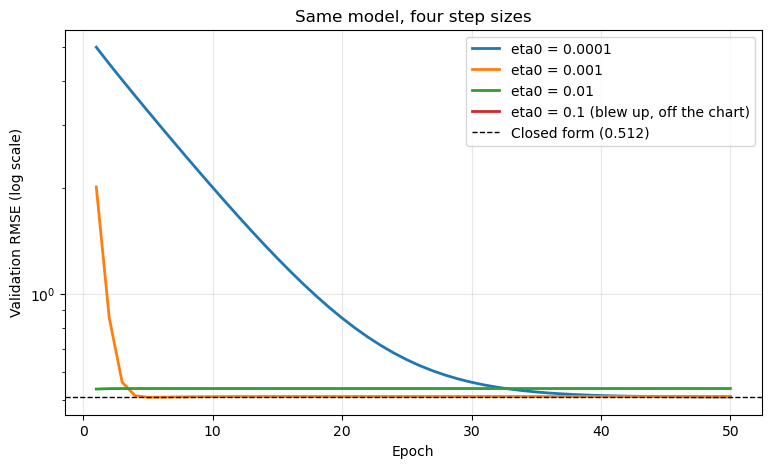

In [28]:
fig, ax = plt.subplots(figsize=(9, 5))
for eta, curve in curves.items():
	shown = np.where(curve < 10, curve, np.nan)   # hide values that blew up, so the plot stays readable
	ax.plot(range(1, N_EPOCHS + 1), shown, linewidth=2, label=f"eta0 = {eta}" + (" (blew up, off the chart)" if np.isnan(shown).all() else ""))
ax.axhline(bottom, color="black", linestyle="--", linewidth=1, label=f"Closed form ({bottom:.3f})")
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation RMSE (log scale)")
ax.set_title("Same model, four step sizes")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 5c. Why SGD needs scaling

SGD uses **one step size for every column**. Look at how differently the columns are spread out before scaling:

In [29]:
pd.DataFrame({
	"sd before scaling": train[COLUMNS].std(),
	"sd after scaling": pd.DataFrame(z_train, columns=COLUMNS).std(),
}).round(3)

,sd before scaling,sd after scaling
Log GDP per capita,1.153,1.0
GDP hinge 10.3,0.231,1.0
GDP hinge 10.9,0.075,1.0
Life exp hinge 57.5,5.480,1.0
Social support,0.122,1.0
Social hinge 0.84,0.041,1.0
Freedom to make life choices,0.141,1.0
Positive affect,0.109,1.0
Perceptions of corruption,0.182,1.0


A step size that is safe for the widest column (Life exp hinge) is far too small for the narrowest ones (Social hinge, GDP hinge 10.9), so those coefficients barely move. A step size big enough for the narrow ones blows up on the wide one. Scaling puts every column on the same spread, so one step size suits them all.

Below: SGD on the **unscaled** columns with two small step sizes, against scaled SGD from 5b.

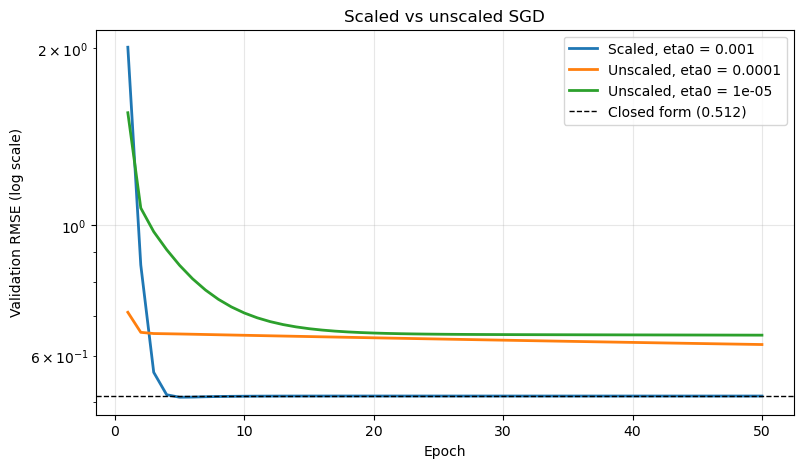

Unscaled eta0=0.0001: epoch 50 RMSE 0.6267
Unscaled eta0=1e-05: epoch 50 RMSE 0.6502
Scaled eta0=0.001:    epoch 50 RMSE 0.5122


In [30]:
unscaled_curves = {}
for eta in [0.0001, 0.00001]:
	step_model = SGDRegressor(penalty=None, learning_rate="constant", eta0=eta, random_state=42)
	curve = []
	with warnings.catch_warnings():
		warnings.simplefilter("ignore")
		for epoch in range(N_EPOCHS):
			step_model.partial_fit(train[COLUMNS].values, train[TARGET])
			curve.append(rmse_of(val[TARGET], step_model.predict(val[COLUMNS].values)))
	unscaled_curves[eta] = np.array(curve)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1, N_EPOCHS + 1), curves[0.001], linewidth=2, label="Scaled, eta0 = 0.001")
for eta, curve in unscaled_curves.items():
	ax.plot(range(1, N_EPOCHS + 1), curve, linewidth=2, label=f"Unscaled, eta0 = {eta}")
ax.axhline(bottom, color="black", linestyle="--", linewidth=1, label=f"Closed form ({bottom:.3f})")
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation RMSE (log scale)")
ax.set_title("Scaled vs unscaled SGD")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

for eta, curve in unscaled_curves.items():
	print(f"Unscaled eta0={eta}: epoch {N_EPOCHS} RMSE {curve[-1]:.4f}")
print(f"Scaled eta0=0.001:    epoch {N_EPOCHS} RMSE {curves[0.001][-1]:.4f}")

## 5d. The penalty: what it is for

A penalty (Ridge = L2, Lasso = L1, Elastic Net = a mix) pulls the coefficients toward 0. It exists to fix **overfitting**: a model that fits its training rows much better than new rows.

So first: is this model overfitting? Compare its training RMSE with its validation RMSE on the same 20 folds.

In [31]:
pd.DataFrame({
	"mean RMSE": [closed_train.mean(), closed_val.mean()],
}, index=["Training (rows it learned from)", "Validation (rows it never saw)"]).round(4)

,mean RMSE
Training (rows it learned from),0.5117
Validation (rows it never saw),0.5162


Now try the penalty over a much wider range of strengths (`alpha`) than the assignment's three, to see where it starts to do anything. The left plots show what happens to each coefficient; the right plot shows the validation RMSE.

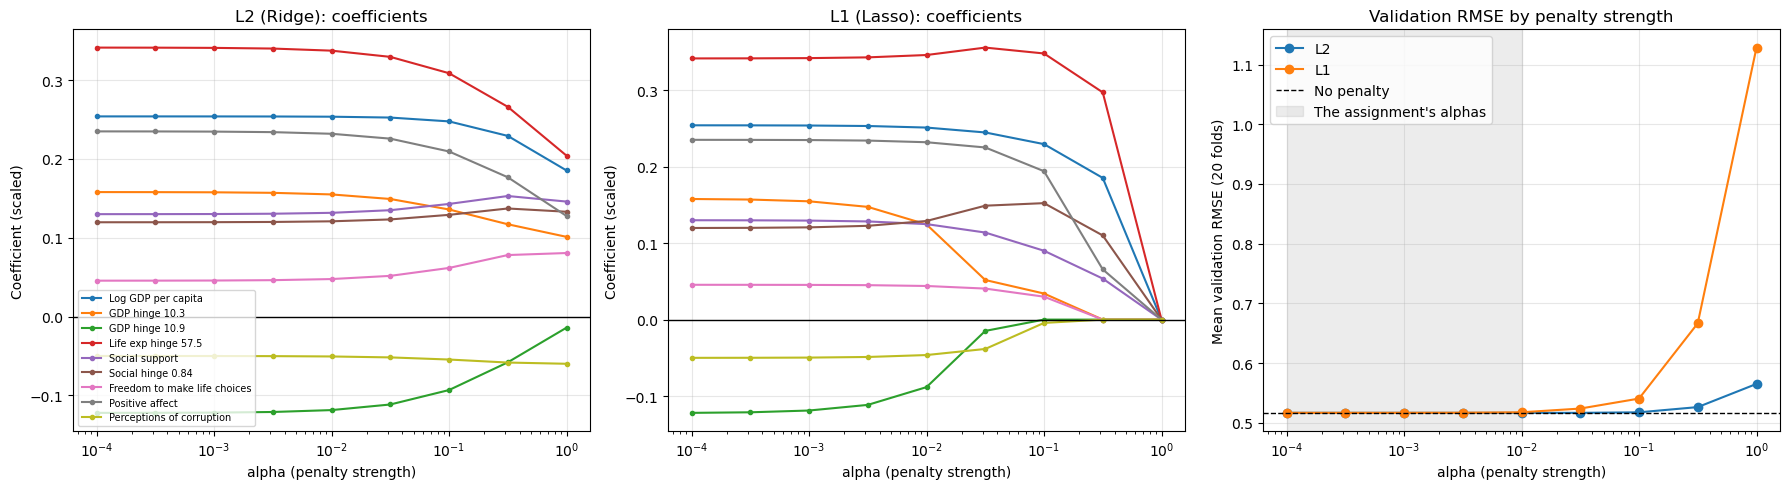

In [32]:
alphas = np.logspace(-4, 0, 9)   # 0.0001 up to 1

paths = {}
for penalty in ["l2", "l1"]:
	path = []
	for alpha in alphas:
		fitted = make_pipeline(StandardScaler(), SGDRegressor(penalty=penalty, alpha=alpha, random_state=42))
		fitted.fit(complete[COLUMNS], complete[TARGET])
		path.append(fitted[-1].coef_)
	paths[penalty] = pd.DataFrame(path, index=alphas, columns=COLUMNS)

penalty_rmse = {
	penalty: [cv_model(complete, COLUMNS, make_pipeline(StandardScaler(), SGDRegressor(penalty=penalty, alpha=alpha, random_state=42)))[0].mean() for alpha in alphas]
	for penalty in ["l2", "l1"]
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, penalty, title in [(axes[0], "l2", "L2 (Ridge): coefficients"), (axes[1], "l1", "L1 (Lasso): coefficients")]:
	for column in COLUMNS:
		ax.plot(alphas, paths[penalty][column], marker="o", markersize=3, label=column)
	ax.axhline(0, color="black", linewidth=1)
	ax.set_xscale("log")
	ax.set_xlabel("alpha (penalty strength)")
	ax.set_ylabel("Coefficient (scaled)")
	ax.set_title(title)
	ax.grid(alpha=0.3)
axes[0].legend(fontsize=7)

for penalty in ["l2", "l1"]:
	axes[2].plot(alphas, penalty_rmse[penalty], marker="o", label=penalty.upper())
axes[2].axhline(sgd_val.mean(), color="black", linestyle="--", linewidth=1, label="No penalty")
axes[2].axvspan(1e-4, 1e-2, color="gray", alpha=0.15, label="The assignment's alphas")
axes[2].set_xscale("log")
axes[2].set_xlabel("alpha (penalty strength)")
axes[2].set_ylabel("Mean validation RMSE (20 folds)")
axes[2].set_title("Validation RMSE by penalty strength")
axes[2].grid(alpha=0.3)
axes[2].legend()
plt.tight_layout()
plt.show()

## The idea to keep

- **SGD** reaches the same line as the closed form, by walking downhill in small steps.
- **Learning rate:** too small walks slowly, too large overshoots or blows up, in between works. A step that stays large can also stop *near* the bottom instead of *at* it, which is what the big notebook's flat epoch curve was.
- **Scaling:** SGD uses one step size for every column, so the columns must be on the same spread.
- **Penalty:** it fixes overfitting. With 9 columns and 1,374 rows there is almost none to fix, so small penalties change nothing and large ones only make the fit worse.

That covers every question in the assignment.

## Your Turn

1. In 5a, closed form and SGD found nearly the same coefficients. So what is the actual difference between them?
2. In 5b, what goes wrong when the learning rate is too small? Too large? And what happened at `eta0 = 0.01`?
3. In 5c, why does SGD need scaling when the closed form does not?
4. In 5d, training and validation RMSE are nearly equal. What does that say about overfitting, and why does it explain why the assignment's penalties barely changed anything?
5. In the 5d plots, what happens to the coefficients and the RMSE as alpha grows? What does L1 do that L2 does not?

_Your answers:_

1. The difference between them is how they get there. Sgd steps down to find the best coefficient and the closed form does it in one sweep
2. When the learning rate is too small, it takes too many iterations to reach a final solution, thus causing useless computation. And when it is too large, it can overstep, blow up or actually never find the correct solution
3. SGD needs scaling because it steps each coefficient by the same amount each time and if the scale of one feature is much larger than the others this will affect the overall step size used across each feature.
4. I don't know.
5. I don't know.